In [56]:
# 1. Importing the packages
import keras
import random
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from keras.models import Sequential
from keras.datasets import mnist

In [57]:
# 2. Loading the MNIST dataset
(x_train,y_train),(x_test,y_test)=mnist.load_data()

In [58]:
# 3. Normalizing image pixel values
x_train=x_train/255
x_test=x_test/255

In [59]:
# 4. Building the feedforward neural network
model=Sequential()

# Input preparation: flatten each 28x28 image into 784 features
model.add(keras.layers.Flatten(input_shape=(28,28)))

# Hidden layer: 128 neurons with ReLU activation
model.add(keras.layers.Dense(128,activation='relu'))

# Output layer: original notebook uses 128 softmax outputs
model.add(keras.layers.Dense(10,activation='softmax'))

In [51]:
# 5. Configuring training: optimizer, loss function, and metric
model.compile(optimizer='sgd',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

In [52]:
# 6. Training for five epochs
H=model.fit(x_train,y_train,validation_data=(x_test,y_test),epochs=5)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8408 - loss: 0.6295 - val_accuracy: 0.9021 - val_loss: 0.3609
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9055 - loss: 0.3392 - val_accuracy: 0.9194 - val_loss: 0.2996
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9177 - loss: 0.2930 - val_accuracy: 0.9241 - val_loss: 0.2671
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9265 - loss: 0.2627 - val_accuracy: 0.9338 - val_loss: 0.2416
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9332 - loss: 0.2390 - val_accuracy: 0.9364 - val_loss: 0.2242


In [53]:
# 7. Evaluating the trained model on the supplied test split
test_loss,test_acc=model.evaluate(x_test,y_test)
print("Loss: %.3f" % test_loss)
print("Accuracy: %.3f" % test_acc)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9364 - loss: 0.2242
Loss: 0.224
Accuracy: 0.936


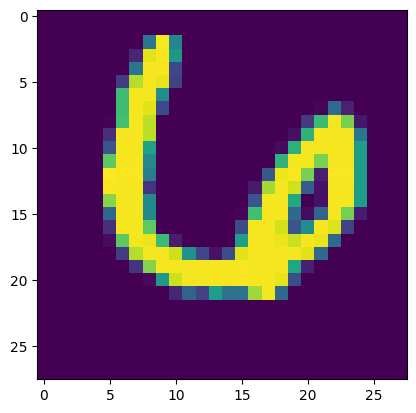

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  
The handwritten number in the image is 6


In [54]:
# 8. Selecting and displaying one test image, then print its predicted class
n=random.randint(0,9999)
plt.imshow(x_test[n])
plt.show()

prediction=model.predict(x_test)
print("The handwritten number in the image is %d" % np.argmax(prediction[n]))

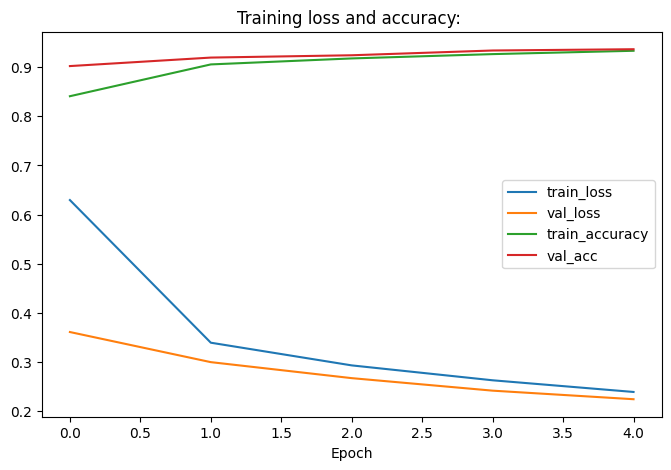

In [55]:
# 9. Visualizing loss and accuracy across epochs
plt.figure(figsize=(8,5))
plt.plot(H.history['loss'],label='train_loss')
plt.plot(H.history['val_loss'],label='val_loss')
plt.plot(H.history['accuracy'],label='train_accuracy')
plt.plot(H.history['val_accuracy'],label='val_acc')
plt.title("Training loss and accuracy: ")
plt.xlabel("Epoch")
plt.legend()
plt.show()